In [4]:
# Part 1

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


CSV_PATH = r"C:\Users\nikitrh\Downloads\ObesityDataSet_raw_and_data_sinthetic.csv"

df = pd.read_csv(CSV_PATH)


df.columns = df.columns.str.strip()

for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].astype("string").str.strip()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Dataset shape: (2111, 17)

Column names:
['Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight', 'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS', 'NObeyesdad']


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [5]:
# Part 2

def find_column(candidates, required=True):
    for name in candidates:
        if name in df.columns:
            return name

    lower_map = {str(c).lower(): c for c in df.columns}

    for name in candidates:
        if name.lower() in lower_map:
            return lower_map[name.lower()]

    if required:
        raise KeyError(
            f"Column not found: {candidates}\n"
            f"Available columns: {df.columns.tolist()}"
        )

    return None


category_col = find_column([
    "NObeyesdad", "N Obeyesdad",
    "ObesityCategory", "Obesity Category", "Obesity"
])

gender_col = find_column(["Gender", "gender"])

height_col = find_column(["Height", "height"], required=False)
weight_col = find_column(["Weight", "weight"], required=False)
bmi_col = find_column(["BMI", "Bmi", "bmi"], required=False)

activity_col = find_column([
    "FAF", "Physical Activity Frequency",
    "PhysicalActivity", "Physical Activity"
], required=False)

food_col = find_column([
    "FAVC", "Frequent consumption of high caloric food",
    "HighCalorieFood"
], required=False)

transport_col = find_column([
    "MTRANS", "Main transportation mode",
    "Transportation", "Transport"
], required=False)


if bmi_col is None:
    if height_col is None or weight_col is None:
        raise ValueError("BMI or both Height and Weight columns are required.")

    df[height_col] = pd.to_numeric(df[height_col], errors="coerce")
    df[weight_col] = pd.to_numeric(df[weight_col], errors="coerce")

    df["BMI_Calculated"] = (
        df[weight_col] / (df[height_col] ** 2)
    )

    bmi_col = "BMI_Calculated"


df[bmi_col] = pd.to_numeric(df[bmi_col], errors="coerce")


df = df.dropna(subset=[category_col, gender_col, bmi_col]).copy()

print("Preprocessing completed!")
print("Records remaining:", len(df))
print("Obesity category column:", category_col)
print("Gender column:", gender_col)
print("BMI column:", bmi_col)

Preprocessing completed!
Records remaining: 2111
Obesity category column: NObeyesdad
Gender column: Gender
BMI column: BMI_Calculated


In [6]:
# Part 3

preferred_categories = [
    "Insufficient_Weight",
    "Normal_Weight",
    "Overweight_Level_I",
    "Overweight_Level_II",
    "Obesity_Type_I",
    "Obesity_Type_II",
    "Obesity_Type_III"
]

present_categories = df[category_col].astype(str).unique().tolist()

category_order = [
    c for c in preferred_categories if c in present_categories
]

category_order += [
    c for c in present_categories if c not in category_order
]

category_colors = {
    "Insufficient_Weight": "#1f77b4",
    "Normal_Weight": "#ff7f0e",
    "Overweight_Level_I": "#2ca02c",
    "Overweight_Level_II": "#d62728",
    "Obesity_Type_I": "#9467bd",
    "Obesity_Type_II": "#8c564b",
    "Obesity_Type_III": "#e377c2"
}

colors = [
    category_colors.get(category, "#7f7f7f")
    for category in category_order
]

plt.rcParams.update({
    "font.size": 9,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 9
})

print("Categories:", category_order)
print("Number of records:", len(df))

Categories: ['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']
Number of records: 2111


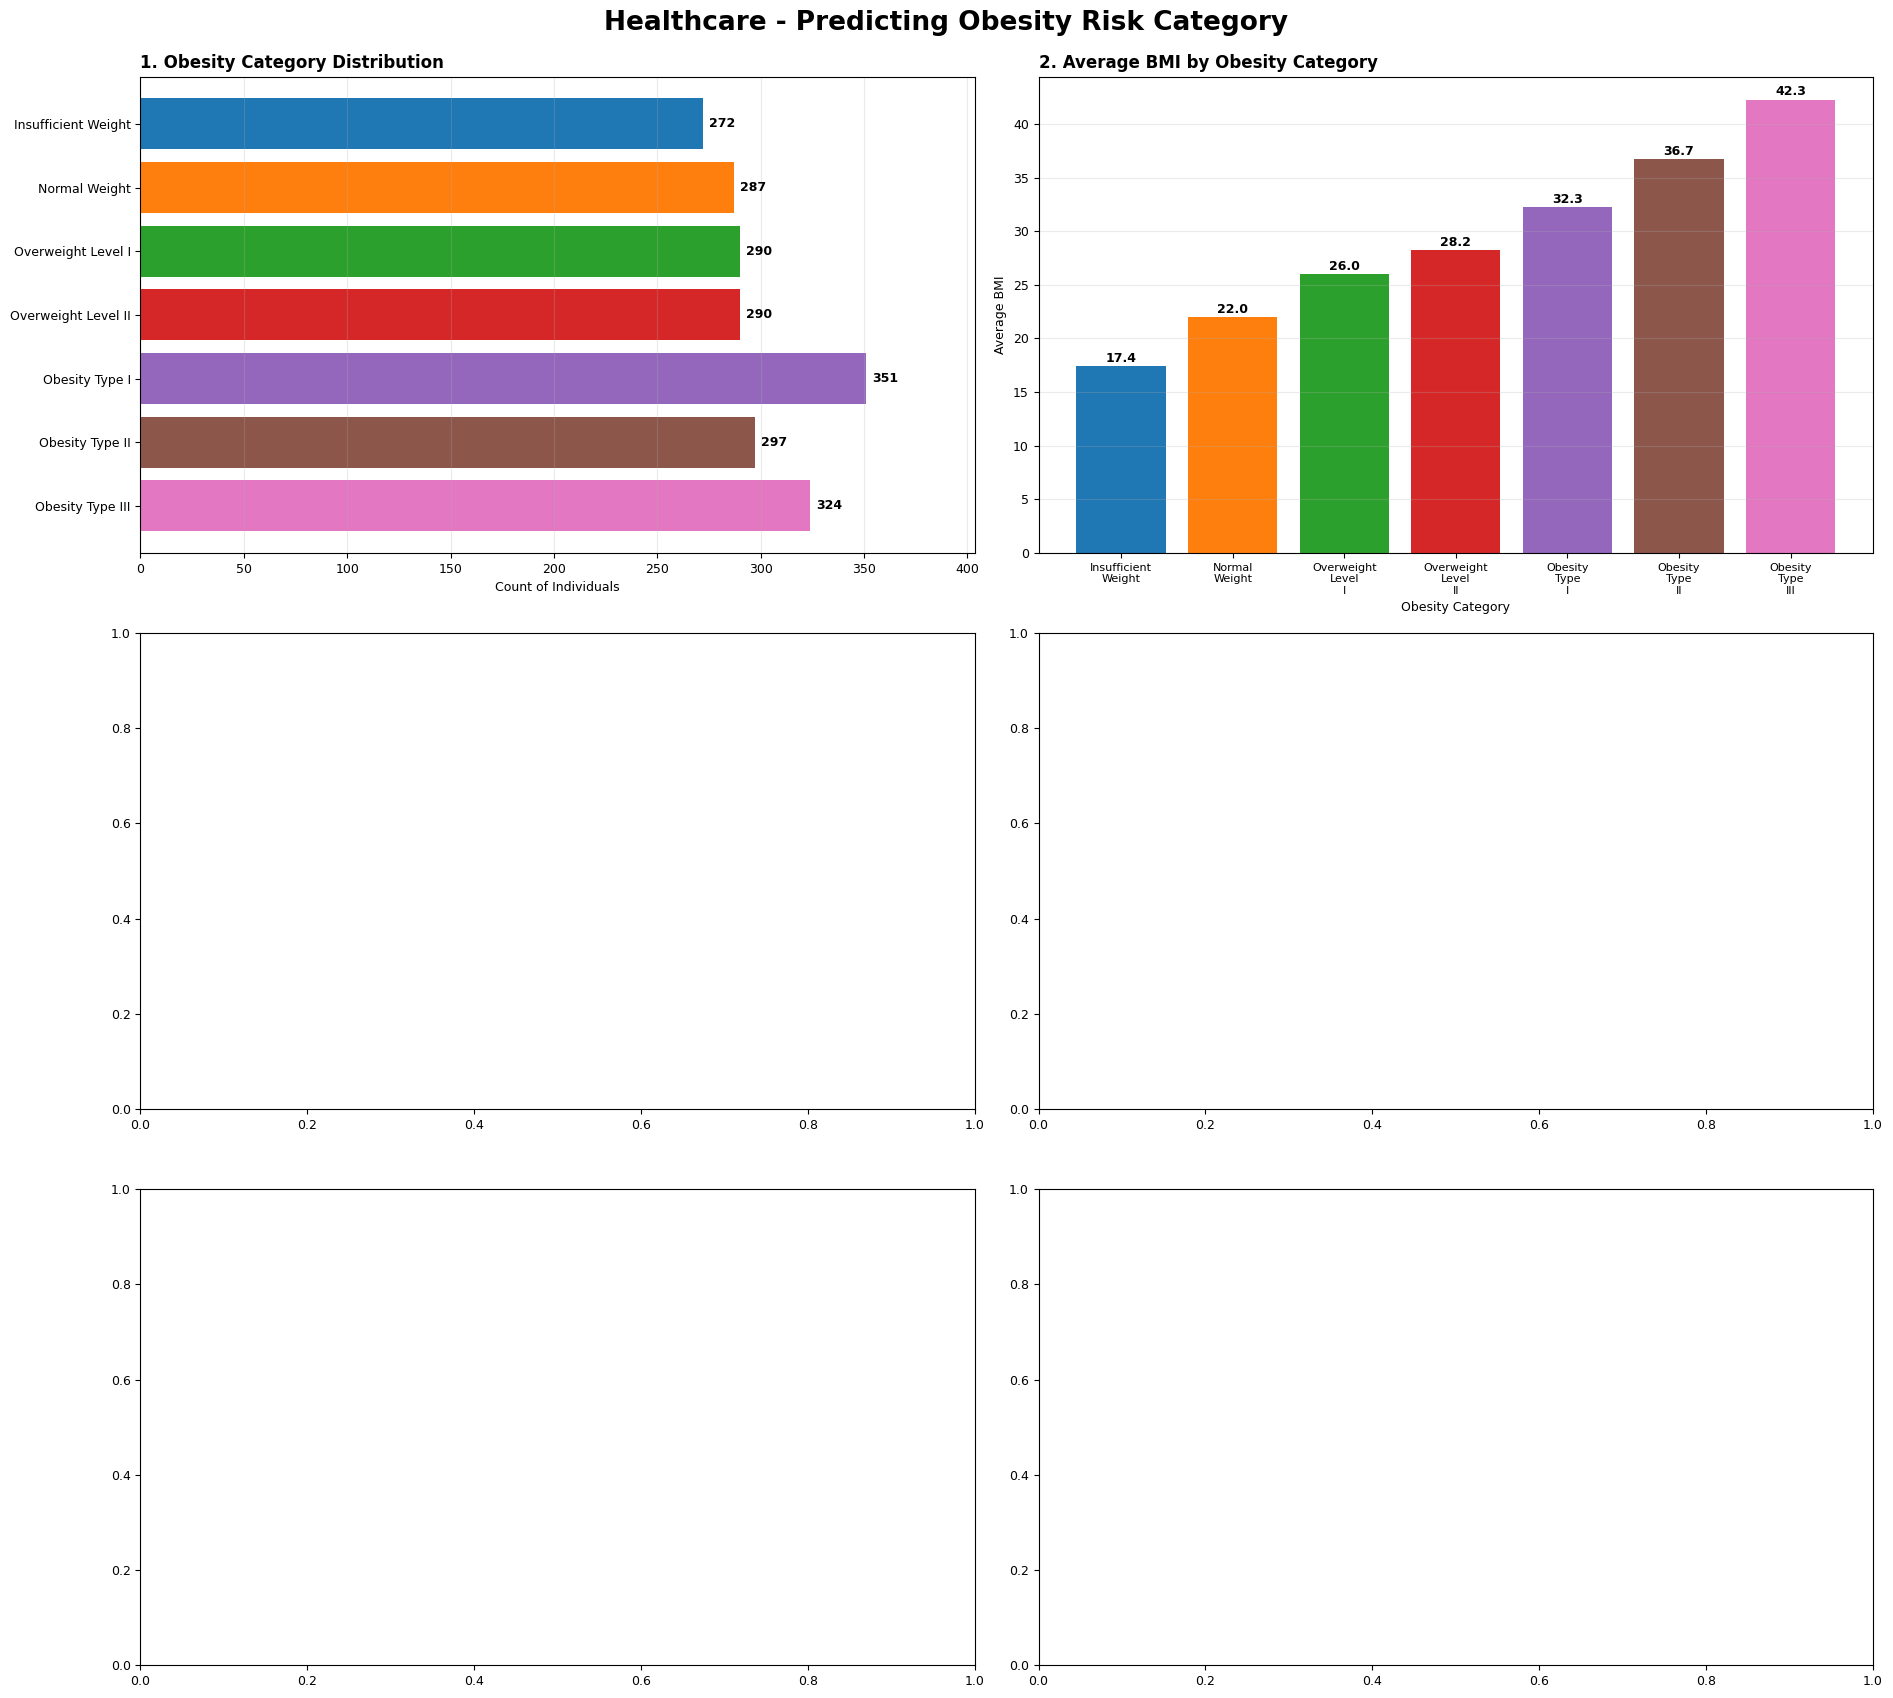

In [7]:
# Part 4

fig, axes = plt.subplots(3, 2, figsize=(19, 17))

fig.suptitle(
    "Healthcare - Predicting Obesity Risk Category",
    fontsize=19,
    fontweight="bold",
    y=0.995
)

axes = axes.flatten()

# Graph 1: Obesity Category Distribution
ax = axes[0]

category_counts = (
    df[category_col]
    .value_counts()
    .reindex(category_order)
    .fillna(0)
)

bars = ax.barh(
    [c.replace("_", " ") for c in category_order],
    category_counts.values,
    color=colors
)

ax.invert_yaxis()
ax.set_title("1. Obesity Category Distribution", loc="left")
ax.set_xlabel("Count of Individuals")
ax.grid(axis="x", alpha=0.25)

for bar, value in zip(bars, category_counts.values):
    ax.text(
        value + 3,
        bar.get_y() + bar.get_height() / 2,
        str(int(value)),
        va="center",
        fontweight="bold"
    )

ax.set_xlim(0, max(category_counts.max() * 1.15, 1))


# Graph 2: Average BMI by Obesity Category
ax = axes[1]

average_bmi = (
    df.groupby(category_col)[bmi_col]
    .mean()
    .reindex(category_order)
)

bars = ax.bar(
    range(len(category_order)),
    average_bmi.values,
    color=colors
)

ax.set_title("2. Average BMI by Obesity Category", loc="left")
ax.set_ylabel("Average BMI")
ax.set_xlabel("Obesity Category")
ax.set_xticks(range(len(category_order)))
ax.set_xticklabels(
    [c.replace("_", "\n") for c in category_order],
    fontsize=8
)
ax.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, average_bmi.values):
    if pd.notna(value):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.4,
            f"{value:.1f}",
            ha="center",
            fontweight="bold"
        )

plt.tight_layout()
plt.show()

In [13]:
# Part 5

def create_stacked_chart(ax, factor_col, title, xlabel):

    if factor_col is None or factor_col not in df.columns:
        ax.axis("off")
        ax.text(
            0.5, 0.5,
            f"Required field not found:\n{xlabel}",
            ha="center",
            va="center",
            transform=ax.transAxes
        )
        ax.set_title(title, loc="left")
        return

    temp = df[[factor_col, category_col]].dropna().copy()

    temp[factor_col] = temp[factor_col].astype(str)
    temp[category_col] = temp[category_col].astype(str)

    pivot = pd.crosstab(
        temp[factor_col],
        temp[category_col]
    ).reindex(columns=category_order, fill_value=0)

    labels = pivot.index.tolist()

    try:
        labels = sorted(labels, key=float)
    except (ValueError, TypeError):
        labels = sorted(labels)

    pivot = pivot.reindex(labels)

    x = np.arange(len(labels))
    bottom = np.zeros(len(labels))

    for category, color in zip(category_order, colors):
        values = pivot[category].to_numpy()

        ax.bar(
            x,
            values,
            bottom=bottom,
            color=color,
            label=category.replace("_", " "),
            width=0.7
        )

        bottom += values

    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_title(title, loc="left")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Number of Individuals")
    ax.grid(axis="y", alpha=0.2)

    ax.legend(
        title="Obesity Category",
        fontsize=7,
        title_fontsize=8,
        loc="upper left",
        bbox_to_anchor=(1.01, 1),
        frameon=False
    )

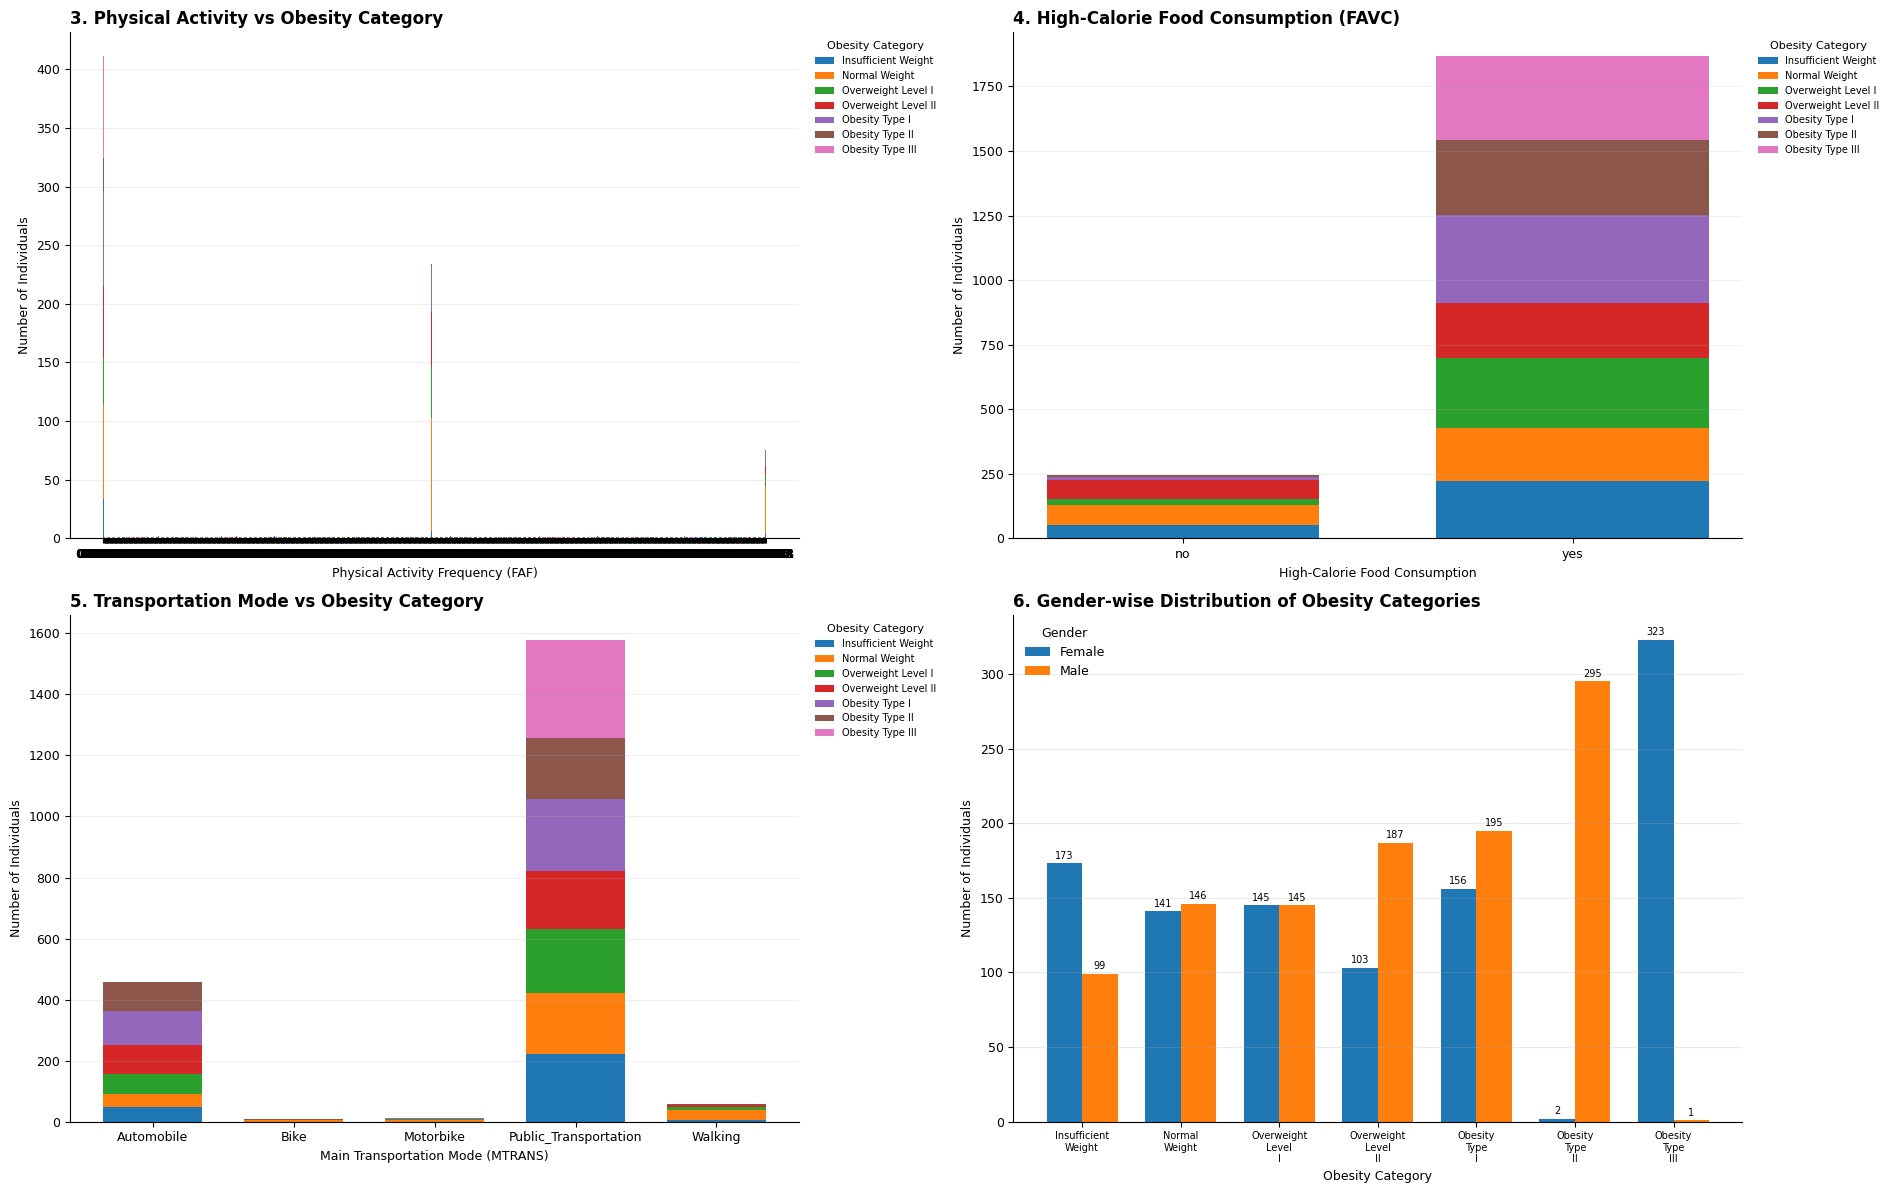

In [10]:
# Part 6

fig, axes2 = plt.subplots(2, 2, figsize=(19, 12))
axes2 = axes2.flatten()

# Graph 3: Physical Activity vs Obesity
create_stacked_chart(
    axes2[0],
    activity_col,
    "3. Physical Activity vs Obesity Category",
    "Physical Activity Frequency (FAF)"
)

# Graph 4: High-Calorie Food Consumption
create_stacked_chart(
    axes2[1],
    food_col,
    "4. High-Calorie Food Consumption (FAVC)",
    "High-Calorie Food Consumption"
)

# Graph 5: Transportation Mode vs Obesity
create_stacked_chart(
    axes2[2],
    transport_col,
    "5. Transportation Mode vs Obesity Category",
    "Main Transportation Mode (MTRANS)"
)

# Graph 6: Gender-wise Obesity Distribution
ax = axes2[3]

gender_data = df[[category_col, gender_col]].dropna().copy()
gender_data[category_col] = gender_data[category_col].astype(str)
gender_data[gender_col] = gender_data[gender_col].astype(str)

gender_pivot = pd.crosstab(
    gender_data[category_col],
    gender_data[gender_col]
).reindex(category_order, fill_value=0)

available_genders = gender_pivot.columns.tolist()

gender_order = []

for wanted in ["Female", "Male"]:
    match = next(
        (g for g in available_genders if g.lower() == wanted.lower()),
        None
    )
    if match is not None:
        gender_order.append(match)

gender_order += [
    g for g in available_genders if g not in gender_order
]

x = np.arange(len(category_order))
bar_width = 0.36
gender_palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd"]

for i, gender in enumerate(gender_order):
    values = gender_pivot[gender].to_numpy()

    offset = (i - (len(gender_order) - 1) / 2) * bar_width

    bars = ax.bar(
        x + offset,
        values,
        bar_width,
        label=gender,
        color=gender_palette[i % len(gender_palette)]
    )

    for bar, value in zip(bars, values):
        if value > 0:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                value + 3,
                str(int(value)),
                ha="center",
                fontsize=7
            )

ax.set_title(
    "6. Gender-wise Distribution of Obesity Categories",
    loc="left"
)
ax.set_ylabel("Number of Individuals")
ax.set_xlabel("Obesity Category")
ax.set_xticks(x)
ax.set_xticklabels(
    [c.replace("_", "\n") for c in category_order],
    fontsize=7
)
ax.legend(title="Gender", frameon=False)
ax.grid(axis="y", alpha=0.25)

for ax in axes2:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

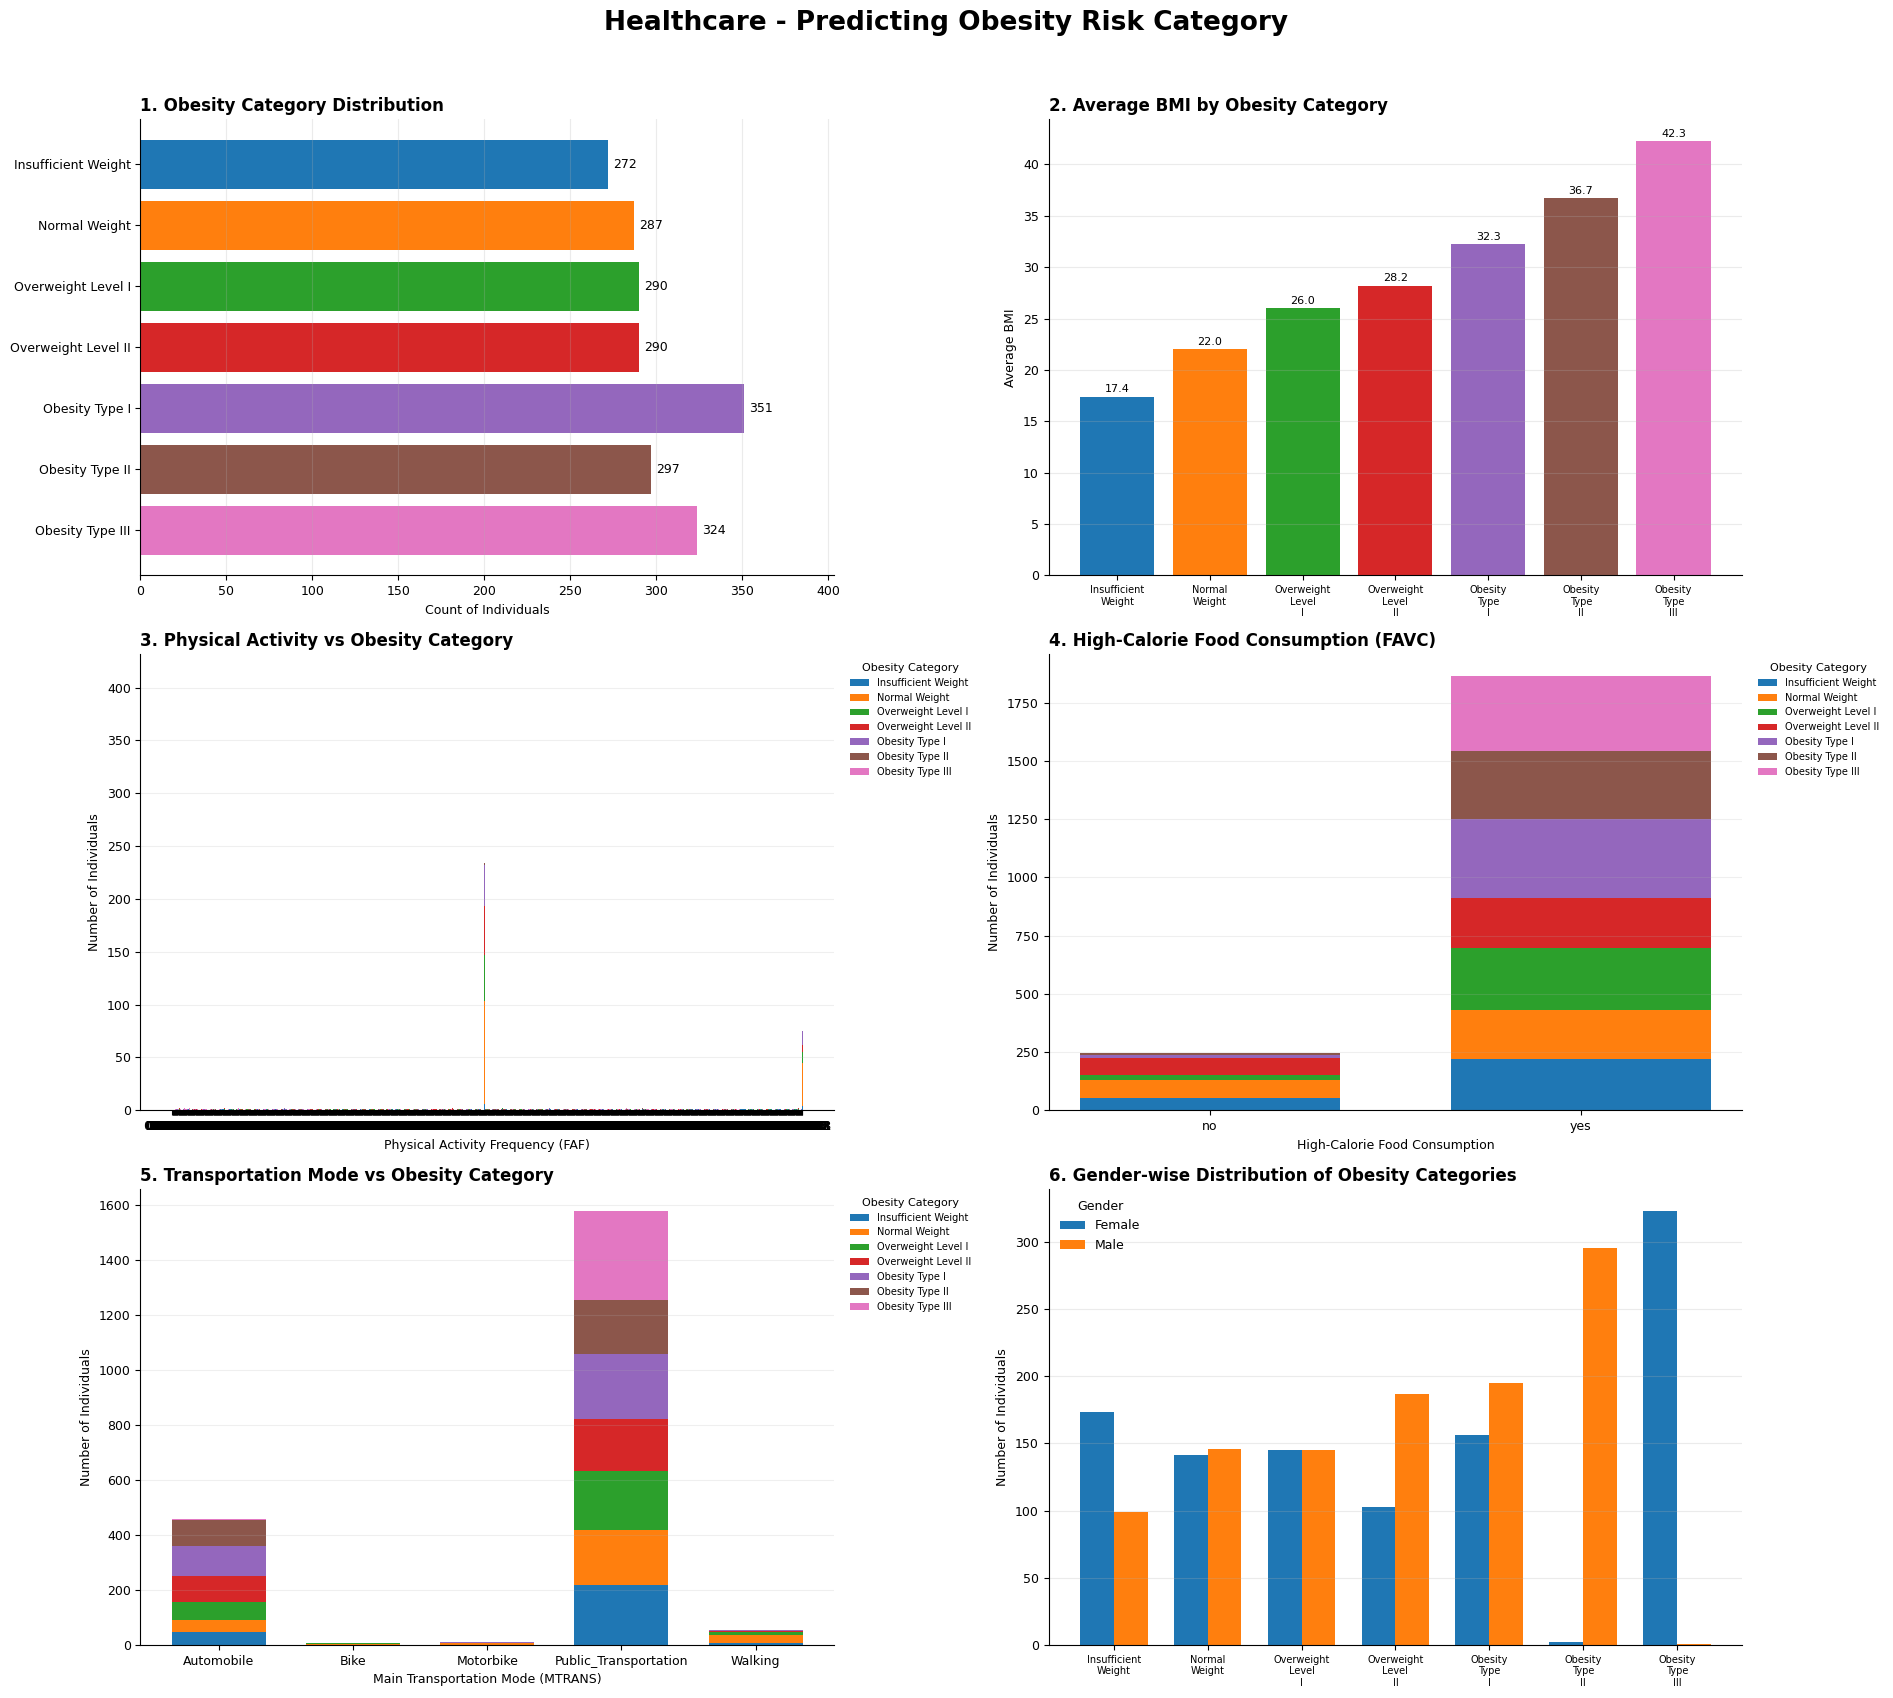

Dashboard created successfully!
Saved as: obesity_analysis_dashboard.png


In [11]:
# Part 7

fig, axes = plt.subplots(3, 2, figsize=(19, 17))
fig.suptitle(
    "Healthcare - Predicting Obesity Risk Category",
    fontsize=19,
    fontweight="bold",
    y=0.995
)

axes = axes.flatten()

# Graph 1: Category Distribution
category_counts = (
    df[category_col].value_counts()
    .reindex(category_order).fillna(0)
)

bars = axes[0].barh(
    [c.replace("_", " ") for c in category_order],
    category_counts.values,
    color=colors
)
axes[0].invert_yaxis()
axes[0].set_title("1. Obesity Category Distribution", loc="left")
axes[0].set_xlabel("Count of Individuals")
axes[0].grid(axis="x", alpha=0.25)

for bar, value in zip(bars, category_counts.values):
    axes[0].text(
        value + 3,
        bar.get_y() + bar.get_height() / 2,
        str(int(value)),
        va="center"
    )

axes[0].set_xlim(0, max(category_counts.max() * 1.15, 1))

# Graph 2: Average BMI
average_bmi = (
    df.groupby(category_col)[bmi_col]
    .mean().reindex(category_order)
)

bars = axes[1].bar(
    range(len(category_order)),
    average_bmi.values,
    color=colors
)
axes[1].set_title("2. Average BMI by Obesity Category", loc="left")
axes[1].set_ylabel("Average BMI")
axes[1].set_xticks(range(len(category_order)))
axes[1].set_xticklabels(
    [c.replace("_", "\n") for c in category_order],
    fontsize=7
)
axes[1].grid(axis="y", alpha=0.25)

for bar, value in zip(bars, average_bmi.values):
    if pd.notna(value):
        axes[1].text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.4,
            f"{value:.1f}",
            ha="center",
            fontsize=8
        )

# Graphs 3, 4 and 5
create_stacked_chart(
    axes[2], activity_col,
    "3. Physical Activity vs Obesity Category",
    "Physical Activity Frequency (FAF)"
)

create_stacked_chart(
    axes[3], food_col,
    "4. High-Calorie Food Consumption (FAVC)",
    "High-Calorie Food Consumption"
)

create_stacked_chart(
    axes[4], transport_col,
    "5. Transportation Mode vs Obesity Category",
    "Main Transportation Mode (MTRANS)"
)

# Graph 6: Gender Distribution
gender_pivot = pd.crosstab(
    df[category_col].astype(str),
    df[gender_col].astype(str)
).reindex(category_order, fill_value=0)

gender_order = [
    g for g in ["Female", "Male"]
    if g in gender_pivot.columns
]
gender_order += [
    g for g in gender_pivot.columns if g not in gender_order
]

x = np.arange(len(category_order))
bar_width = 0.36

for i, gender in enumerate(gender_order):
    offset = (i - (len(gender_order) - 1) / 2) * bar_width
    axes[5].bar(
        x + offset,
        gender_pivot[gender].to_numpy(),
        bar_width,
        label=gender
    )

axes[5].set_title(
    "6. Gender-wise Distribution of Obesity Categories",
    loc="left"
)
axes[5].set_ylabel("Number of Individuals")
axes[5].set_xticks(x)
axes[5].set_xticklabels(
    [c.replace("_", "\n") for c in category_order],
    fontsize=7
)
axes[5].legend(title="Gender", frameon=False)
axes[5].grid(axis="y", alpha=0.25)

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.975])

plt.savefig(
    "obesity_analysis_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Dashboard created successfully!")
print("Saved as: obesity_analysis_dashboard.png")